## Selección de características fuera y dentro de la validación cruzada


En los problemas de aprendizaje automático es habitual trabajar con conjuntos de datos que contienen numerosas características. Sin embargo, no todas las variables aportan información útil para realizar predicciones.

La **selección de características** consiste en identificar un subconjunto de variables relevantes para el problema, con el objetivo de simplificar el modelo y, potencialmente, mejorar su capacidad de generalización.

Uno de los métodos que utilizaremos es `SelectKBest`, que permite seleccionar las \(k\) características con mayor puntuación según un criterio estadístico.

No obstante, la selección de características debe realizarse respetando el procedimiento de evaluación.

### ¿Dónde aparece el problema?

Supongamos que dividimos un conjunto de datos en diferentes particiones para realizar validación cruzada.

Si seleccionamos las características utilizando todas las observaciones antes de realizar esa división, estamos utilizando también información de las observaciones que posteriormente se emplearán para evaluar el modelo.

Esto provoca una **fuga de información**.

Como consecuencia, el rendimiento estimado puede resultar excesivamente optimista y no representar la capacidad real del modelo para realizar predicciones sobre datos nuevos.

### Regla fundamental

Cualquier transformación o procedimiento que aprenda información a partir de los datos debe ajustarse exclusivamente utilizando las observaciones de entrenamiento de cada partición.

Esta regla también se aplica a otros procedimientos, como la imputación de valores ausentes, el escalado y la reducción de dimensionalidad.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification

from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

from sklearn.pipeline import Pipeline

## Diseño del experimento

Para comprobar el efecto de la fuga de información, construiremos un conjunto de datos sintético de clasificación.

El conjunto tendrá muchas características, pero solamente unas pocas contendrán información útil para distinguir las clases.

Compararemos dos procedimientos:

**Procedimiento A. Selección antes de la validación cruzada**

Se seleccionarán las características utilizando todas las observaciones y sus etiquetas. Posteriormente, se realizará la validación cruzada sobre el conjunto de características seleccionado.

**Procedimiento B. Selección dentro de la validación cruzada**

La selección de características se realizará de manera independiente en cada partición, utilizando exclusivamente las observaciones de entrenamiento.

El clasificador y los parámetros utilizados serán los mismos en ambos procedimientos, de manera que podamos estudiar cómo influye el lugar en el que se realiza la selección.

In [15]:
X, y = make_classification(
    n_samples=205,
    n_features=1000,
    n_informative=5,
    n_redundant=0,
    n_repeated=0,
    n_classes=2,
    random_state=42
)

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("Número de características:", X.shape[1])

Dimensiones de X: (205, 1000)
Dimensiones de y: (205,)
Número de características: 1000


### Exploración inicial

Antes de entrenar cualquier modelo, conviene examinar la distribución de la variable objetivo.

En los problemas de clasificación, un desequilibrio importante entre las clases puede afectar a la interpretación de determinadas métricas, como el accuracy.

Por ello, calcularemos la frecuencia y el porcentaje de observaciones correspondientes a cada clase.

In [16]:
frecuencia = pd.Series(y).value_counts().sort_index()

porcentaje = (
    pd.Series(y)
    .value_counts(normalize=True)
    .sort_index() * 100
)

resumen_clases = pd.DataFrame({
    'Cantidad': frecuencia,
    'Porcentaje': porcentaje
})

display(resumen_clases)

,Cantidad,Porcentaje
0,104,50.731707
1,101,49.268293


### Establecimiento de un baseline

Antes de comparar los dos procedimientos de selección de características, estableceremos un modelo de referencia o *baseline*.

Un baseline proporciona un punto de comparación sencillo que permite determinar si un modelo está aprendiendo patrones útiles o si sus resultados son similares a los que podríamos obtener mediante una estrategia muy simple.

En este experimento utilizaremos `DummyClassifier`, un clasificador que realiza predicciones siguiendo una estrategia básica, sin aprender relaciones entre las características y la variable objetivo.

Utilizaremos la estrategia `most_frequent`, que predice siempre la clase más frecuente en los datos de entrenamiento de cada partición.

Posteriormente compararemos los resultados de los modelos de regresión logística con este baseline.

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline = DummyClassifier(
    strategy='most_frequent'
)

scores_baseline = cross_val_score(
    baseline,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Accuracy por partición:", scores_baseline)
print("Accuracy medio:", scores_baseline.mean())
print("Desviación estándar:", scores_baseline.std())

Accuracy por partición: [0.51219512 0.51219512 0.51219512 0.51219512 0.48780488]
Accuracy medio: 0.5073170731707317
Desviación estándar: 0.009756097560975618


### Procedimiento A: selección de características antes de la validación cruzada

En este primer procedimiento realizaremos la selección de características utilizando todas las observaciones del conjunto de datos.

Para ello utilizaremos `SelectKBest`, que seleccionará las 10 características con mayor puntuación según el estadístico F de ANOVA (`f_classif`).

Una vez seleccionadas las características, aplicaremos validación cruzada para evaluar un modelo de regresión logística.

**Importante:** este procedimiento es incorrecto desde el punto de vista metodológico.

La selección se realiza utilizando tanto las observaciones que posteriormente se emplearán para entrenar como aquellas que se utilizarán para validar el modelo.

Por tanto, las etiquetas de las observaciones de validación ya han influido en la selección de características antes de comenzar la evaluación.

El objetivo de este experimento es observar cómo esta práctica puede producir una estimación demasiado optimista del rendimiento.

In [3]:
# Seleccionar características utilizando todos los datos

selector = SelectKBest(
    score_func=f_classif,
    k=10
)

X_seleccionado = selector.fit_transform(X, y)

print("Dimensiones originales:", X.shape)
print("Dimensiones después de seleccionar:", X_seleccionado.shape)

Dimensiones originales: (200, 1000)
Dimensiones después de seleccionar: (200, 10)


#### Análisis de la selección

El procedimiento anterior ha seleccionado las 10 características que presentan mayor puntuación estadística respecto a la variable objetivo, utilizando todas las observaciones disponibles.

El problema es que esta selección también ha utilizado las etiquetas de las observaciones que posteriormente formarán parte de los conjuntos de validación.

Por tanto, aunque todavía no hemos entrenado el clasificador, ya hemos introducido información procedente de los datos de validación en el proceso de aprendizaje.

In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

modelo = LogisticRegression(
    max_iter=2000
)

scores_incorrectos = cross_val_score(
    modelo,
    X_seleccionado,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Resultados por partición:", scores_incorrectos)

print("Accuracy medio:", scores_incorrectos.mean())
print("Desviación estándar:", scores_incorrectos.std())

Resultados por partición: [0.9   0.625 0.675 0.825 0.825]
Accuracy medio: 0.7700000000000001
Desviación estándar: 0.10295630140986997


/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


### Procedimiento B: selección de características dentro de la validación cruzada

Ahora repetiremos el experimento, pero corrigiendo el problema anterior.

La selección de características debe realizarse utilizando exclusivamente las observaciones de entrenamiento de cada partición.

Para conseguirlo utilizaremos `Pipeline` de Scikit-learn.

Un pipeline permite encadenar diferentes etapas del proceso de aprendizaje, de manera que cada una se ajuste siguiendo el orden establecido.

En nuestro caso, el pipeline estará formado por:

1. **Selección de características:** `SelectKBest` identificará las 10 características más relevantes utilizando los datos de entrenamiento.
2. **Clasificación:** `LogisticRegression` entrenará el modelo utilizando únicamente las características seleccionadas.

Cuando ejecutemos la validación cruzada, Scikit-learn ajustará el pipeline de manera independiente en cada partición.

Así, las observaciones de validación no intervendrán en la selección de características ni en el entrenamiento del clasificador.

In [5]:
pipeline = Pipeline([
    ('seleccion', SelectKBest(
        score_func=f_classif,
        k=10
    )),
    ('clasificador', LogisticRegression(
        max_iter=2000
    ))
])

In [6]:
scores_correctos = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Resultados por partición:", scores_correctos)

print("Accuracy medio:", scores_correctos.mean())
print("Desviación estándar:", scores_correctos.std())

Resultados por partición: [0.525 0.625 0.675 0.675 0.8  ]
Accuracy medio: 0.6599999999999999
Desviación estándar: 0.0888819441731559


/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/home/jennifer/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Observe los resultados obtenidos mediante el procedimiento correcto.

En este caso, cada partición realiza su propia selección de características utilizando únicamente los datos de entrenamiento.

Por tanto, el rendimiento obtenido constituye una estimación más adecuada de la capacidad de generalización del modelo bajo el esquema de validación utilizado.


In [ ]:
comparacion = pd.DataFrame({
    'Procedimiento': [
        'Baseline',
        'Selección antes de CV',
        'Selección dentro de CV'
    ],
    'Accuracy medio': [
        scores_baseline.mean(),
        scores_incorrectos.mean(),
        scores_correctos.mean()
    ],
    'Desviación estándar': [
        scores_baseline.std(),
        scores_incorrectos.std(),
        scores_correctos.std()
    ]
})

comparacion

,Procedimiento,Accuracy medio,Desviación estándar
0,Baseline,0.507317,0.009756
1,Selección antes de CV,0.770000,0.102956
2,Selección dentro de CV,0.660000,0.088882


In [20]:
resultados_por_particion = pd.DataFrame({
    'Partición': range(1, 6),
    'Baseline': scores_baseline,
    'Selección antes de CV': scores_incorrectos,
    'Selección dentro de CV': scores_correctos
})

display(resultados_por_particion)

,Partición,Baseline,Selección antes de CV,Selección dentro de CV
0,1,0.512195,0.900,0.525
1,2,0.512195,0.625,0.625
2,3,0.512195,0.675,0.675
3,4,0.512195,0.825,0.675
4,5,0.487805,0.825,0.800


### Análisis comparativo

Como se observa en las tablas anteriores, el baseline obtiene un accuracy medio cercano a 0.51, lo que representa el rendimiento de una estrategia sencilla que predice siempre la clase más frecuente.

Por otra parte, el procedimiento que realiza la selección de características antes de la validación cruzada obtiene un accuracy medio de 0.77, mientras que el procedimiento que realiza la selección dentro de cada partición obtiene un accuracy medio de 0.66.

Esta diferencia es importante: el procedimiento incorrecto presenta una estimación del rendimiento considerablemente superior.

Sin embargo, esta mejora aparente no significa que el modelo tenga realmente una mayor capacidad de generalización. Se debe a que la selección de características se realizó utilizando todas las observaciones, incluidas aquellas que posteriormente se utilizaron para validar el modelo.

Por tanto, el procedimiento incorrecto introduce fuga de información y produce una estimación excesivamente optimista del rendimiento.

También debemos considerar la variabilidad de los resultados entre las particiones. Una desviación estándar elevada indica que el rendimiento no se mantiene de forma estable en todas ellas.

Es importante recordar que obtener un resultado elevado o una desviación estándar pequeña no garantiza que el procedimiento experimental sea metodológicamente correcto.

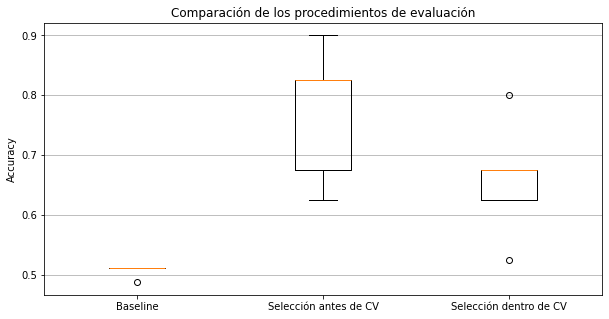

In [21]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    [
        scores_baseline,
        scores_incorrectos,
        scores_correctos
    ],
    tick_labels=[
        'Baseline',
        'Selección antes de CV',
        'Selección dentro de CV'
    ]
)

plt.ylabel('Accuracy')
plt.title('Comparación de los procedimientos de evaluación')

plt.grid(axis='y')
plt.show()

El diagrama de cajas permite comparar la distribución de los resultados obtenidos por los tres procedimientos.

En primer lugar, el baseline presenta una dispersión prácticamente nula, lo que indica que su rendimiento es muy estable entre particiones. Sin embargo, su accuracy medio es aproximadamente 0.51, por lo que constituye una referencia de rendimiento relativamente bajo.

Por otra parte, la selección de características realizada antes de la validación cruzada presenta el accuracy medio más elevado (0.77), pero también una mayor dispersión. Este resultado no debe interpretarse como una evidencia de que el procedimiento sea mejor, ya que existe fuga de información: las etiquetas de todas las observaciones participaron en la selección de características.

Finalmente, la selección de características realizada dentro de cada pliegue obtiene un accuracy medio de 0.66. Aunque sus resultados presentan cierta variabilidad, este procedimiento evita la fuga de información y proporciona una estimación más fiable del rendimiento esperado sobre datos nuevos.

En conclusión, el procedimiento correcto no es necesariamente el que obtiene el mayor accuracy, sino aquel que evalúa el modelo sin utilizar información de las observaciones destinadas a validación.

#### Conclusiones generales

En esta práctica hemos estudiado cómo el procedimiento utilizado para seleccionar características puede afectar a la evaluación de un modelo de aprendizaje automático.

Hemos comparado dos situaciones:

- Seleccionar características utilizando todo el conjunto de datos antes de realizar la validación cruzada.
- Seleccionar características dentro de cada partición, utilizando exclusivamente los datos de entrenamiento.

El primer procedimiento introduce fuga de información porque utiliza indirectamente las etiquetas de las observaciones de validación durante la selección.

El segundo procedimiento evita este problema mediante el uso de un pipeline, que permite ajustar cada etapa del proceso de aprendizaje utilizando únicamente los datos de entrenamiento correspondientes.

### Reflexión final

Imagine que está desarrollando un modelo de aprendizaje automático para una aplicación real y necesita presentar sus resultados.

Un compañero obtiene un accuracy del 98 % seleccionando las características antes de realizar la validación cruzada. Otro obtiene un accuracy del 75 % realizando la selección dentro de cada partición.

1. ¿Cuál de los dos resultados considera más fiable?
2. ¿Qué información necesitaría conocer antes de aceptar los resultados del primer experimento?
3. ¿Por qué no debería elegirse automáticamente el modelo que presenta el mayor accuracy?
4. ¿Qué otros procedimientos de preprocesamiento podrían introducir fuga de información si se realizan antes de la validación cruzada?

**Conclusión fundamental:** una evaluación fiable requiere que todas las etapas que aprenden información de los datos se ejecuten exclusivamente con las observaciones de entrenamiento. Un diseño experimental incorrecto puede producir resultados excesivamente optimistas y conducir a conclusiones equivocadas sobre la calidad de un modelo.